# Bipedal locomotion, part 3: whole-body control

A humanoid standing on two feet has to satisfy a fistful of objectives **at the
same time**: keep both feet planted, shift its weight without toppling, and not
let its torso spin up. These objectives pull on the same 35 velocity
coordinates, and they conflict. **Whole-body control (WBC)** is the standard way
to arbitrate: pose all the objectives as one *quadratic program* (QP) over the
robot's joint accelerations and let least-squares find the best compromise the
robot can actually achieve.

This notebook takes the [Unitree G1](https://www.unitree.com/g1) — a 29-DoF
humanoid, 35 velocity DoF once it floats — and solves **one instantaneous WBC
QP** for it, standing in double support. We pin both feet, ask the center of
mass (CoM) to shift sideways, and damp the body's angular momentum. Then we read
the solution back and check it did what we asked: the feet do not accelerate,
the CoM moves the way it was told, and the contact-vs-CoM trade-off behaves the
way the weights say it should.

> **By the end you will be able to:**
> 1. Write the whole-body-control QP — the map from task objectives to joint
>    accelerations $\ddot q$ — and read off what each term costs.
> 2. Build three concrete tasks for the G1 (contact, CoM, momentum) from
>    jaxterity's centroidal primitives, and stack them into one solve.
> 3. Verify the solution quantitatively: zero contact acceleration, CoM
>    tracking the command, and a clean contact-weight trade-off sweep.
> 4. Reason about WBC **failure modes** — conflicting tasks, a rank-deficient
>    stack, and contact-vs-CoM infeasibility — and recognize them in the numbers.

*Reading time ≈ 20 min. Runtime ≈ 3–6 min on CPU* (most of it MJX's first-call
compile of the centroidal Jacobians).


> **Position in the series.** Parts 1–2 worked in the *reduced* plan — the
> single-rigid-body and linear-inverted-pendulum models, where the robot is a
> point mass plus a flywheel and balance is a 2D capture-point story. Those
> models tell you *where the CoM should go*. This part is where that command
> meets the **full robot**: the WBC takes a CoM objective (the kind Parts 1–2
> produce) and resolves it against the *actual* 35-DoF G1 — every joint, both
> contacts, the real centroidal momentum matrix — instead of a point mass. The
> reduced plan sets the target; the WBC tracks it on the whole body.

> **Out of scope (deliberately).** This part solves the **instantaneous** WBC
> QP: given the current state, what joint accelerations $\ddot q$ best satisfy
> the tasks *right now*. It is an honest single-tick mapping, **not** a closed
> loop. Two things are explicitly Parts 4–5:
> - **Torque-level inverse dynamics** — turning $\ddot q$ into joint torques
>   $\tau$ through the equations of motion with contact-force constraints
>   (the friction cone, torque limits). Here we stop at $\ddot q$.
> - **Closed-loop MJX stepping** — feeding the controller back into the
>   simulator to watch a *dynamic walk* emerge over time. We validate the
>   instantaneous map, not a trajectory.
>
> Keeping the scope this tight is the point: a WBC bug is far easier to find in
> one transparent QP solve than buried inside a closed-loop rollout.


## Setup

We enable **float64** (`jax_enable_x64`) — WBC stacks objectives with weights
spanning five orders of magnitude (contacts at $10^5$, momentum at $10^1$), and
float32 would lose the small tasks in the rounding of the big ones. We seed
NumPy for reproducibility, though this notebook is deterministic — there is no
sampled data anywhere, every number comes from the model.

In [1]:
from jax import config
config.update("jax_enable_x64", True)  # WBC weight spreads need double precision

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mujoco

np.random.seed(0)  # deterministic; no sampled data in this notebook

from jaxterity import zoo
from jaxterity.wbc import CoMTask, ContactTask, MomentumTask, WBCSolver
from jaxterity.wbc.centroidal import (
    centroidal_momentum_matrix,
    com_position,
    contact_jacobian,
)
from jaxterity.wbc.locomotion import foot_body_ids

print("jax x64 enabled:", jax.config.read("jax_enable_x64"))

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'


jax x64 enabled: True


## 1. The floating-base G1 and its state

We load the G1 with a **floating base**: a 6-DoF free joint connects the world
to the pelvis, as a real biped needs. A 3D floating base makes the configuration
and velocity vectors **different lengths** — the single most important fact to
hold onto in this notebook:

- $n_q = 36$ configuration coordinates: base position $[x,y,z]$, base orientation
  as a unit **quaternion** $[w,x,y,z]$ (4 numbers), then the 29 joint angles.
- $n_v = 35$ velocity coordinates: the base angular velocity is a 3-vector, so
  the quaternion's 4 coordinates collapse to **3** in the tangent space.

$n_q \neq n_v$ because a quaternion lives on a 3-sphere: 4 numbers, 3 DoF. **Every
Jacobian in this notebook is $(\cdot, n_v)$** — accelerations live in the
velocity space, not the configuration space. (This is exactly why we do *not*
use a `PostureTask` here: its Jacobian is the identity $I$, which silently
assumes $n_q = n_v$ — true for a fixed-base arm, wrong for a floating base.)

In [2]:
robot = zoo.unitree_g1.load(floating_base=True)
model = robot.build_system()._mjx_model       # the differentiable MJX model
nq, nv = int(model.nq), int(model.nv)
total_mass = float(jnp.sum(model.body_mass))

print(f"nq = {nq} configuration coords  (3 pos + 4 quat + 29 joints)")
print(f"nv = {nv} velocity coords       (3 lin + 3 ang + 29 joints)")
print(f"total mass = {total_mass:.2f} kg")
assert (nq, nv) == (36, 35), "expected the 36/35 floating-base G1"

# Home pose: pelvis at standing height, identity base orientation, joints at 0.
q0 = jnp.array(np.asarray(model.qpos0))
q0 = q0.at[2].set(0.79)                          # pelvis height (m)
q0 = q0.at[3:7].set(jnp.array([1.0, 0.0, 0.0, 0.0]))  # identity quaternion (w,x,y,z)
qd0 = jnp.zeros(nv)                              # at rest

c0 = com_position(model, q0)
print(f"home CoM = {np.round(np.asarray(c0), 4)}  (m, world frame)")

nq = 36 configuration coords  (3 pos + 4 quat + 29 joints)
nv = 35 velocity coords       (3 lin + 3 ang + 29 joints)
total mass = 33.34 kg


home CoM = [2.030e-02 1.000e-04 7.013e-01]  (m, world frame)


## 2. What we are controlling — a rendered frame

Before any math, here is the robot in its home pose. One honesty note up front:
jaxterity's vendored G1 is **mesh-free** — it carries the kinematic tree and the
`<inertial>` elements (mass, CoM, inertia per link) but **no visual geometry**,
because jaxterity drives dynamics from *inertials*, not from meshes. So a raw
render of the model is a blank scene.

To get a faithful, visible picture we synthesize an **inertial skeleton**: a
sphere at each link's inertial frame and a capsule along each link, built with
MuJoCo's `MjSpec` from the *actual* `robot.to_mjcf()`. What you see below is the
real kinematic/inertial tree the WBC controls — the joint positions and link
offsets are the model's, only the drawn geometry is synthesized for the eye.
The render runs **headless** here via `mujoco.Renderer`.

rendered frame (520, 680, 3), non-black pixel fraction = 0.026


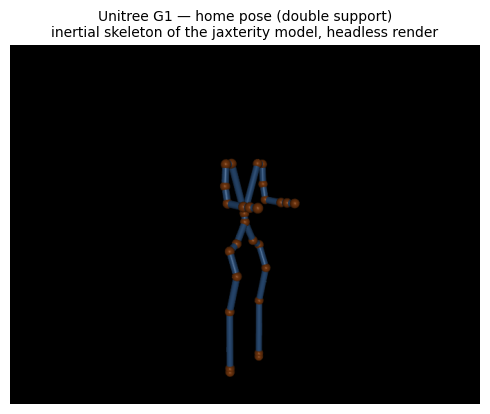

In [3]:
def build_skeleton_model(robot):
    '''Synthesize a visible inertial-skeleton MjModel from the mesh-free G1.

    Adds a sphere at each body's inertial frame and a capsule along each link
    (parent origin -> child origin) so the otherwise-geometry-free model renders.
    The kinematics are untouched; only drawn geometry is added.
    '''
    spec = mujoco.MjSpec.from_string(robot.to_mjcf())
    spec.visual.global_.offwidth = 680     # enlarge offscreen framebuffer
    spec.visual.global_.offheight = 520
    for b in spec.bodies:
        if b.name == "world":
            continue
        joint = b.add_geom()
        joint.type = mujoco.mjtGeom.mjGEOM_SPHERE
        joint.size = [0.025, 0, 0]
        joint.rgba = [0.85, 0.40, 0.10, 1.0]      # joint markers (orange)
        offset = np.array(b.pos)
        L = float(np.linalg.norm(offset))
        parent = b.parent
        if L > 1e-4 and parent is not None and parent.name != "world":
            link = parent.add_geom()              # capsule lives in parent frame
            link.type = mujoco.mjtGeom.mjGEOM_CAPSULE
            link.fromto = [0, 0, 0, offset[0], offset[1], offset[2]]
            link.size = [0.018, 0, 0]
            link.rgba = [0.30, 0.55, 0.85, 1.0]   # link segments (blue)
    return spec.compile()

m_vis = build_skeleton_model(robot)
d_vis = mujoco.MjData(m_vis)
d_vis.qpos[:] = np.asarray(q0)
mujoco.mj_forward(m_vis, d_vis)

renderer = mujoco.Renderer(m_vis, height=520, width=680)
cam = mujoco.MjvCamera()
mujoco.mjv_defaultFreeCamera(m_vis, cam)
cam.distance, cam.azimuth, cam.elevation = 2.2, 130, -8
cam.lookat = [0.0, 0.0, 0.78]
renderer.update_scene(d_vis, cam)
frame = renderer.render()

nonzero = float((frame > 0).mean())
print(f"rendered frame {frame.shape}, non-black pixel fraction = {nonzero:.3f}")
assert nonzero > 0.005, "render came out blank"

fig, ax = plt.subplots(figsize=(5.0, 5.6))
ax.imshow(frame)
ax.axis("off")
ax.set_title("Unitree G1 — home pose (double support)\n"
             "inertial skeleton of the jaxterity model, headless render",
             fontsize=10)
plt.tight_layout()
plt.show()

**Figure 1.** The G1 in its home double-support pose: pelvis at 0.79 m,
identity base orientation, joints at zero. Orange spheres mark link inertial
frames; blue capsules are the links between them. This is the genuine
floating-base kinematic tree the WBC below operates on (36 configuration / 35
velocity coordinates) — only the surface geometry is synthesized, since the
model itself is mesh-free.

## 3. The whole-body-control QP

Each task asserts a desired value for some linear function of the joint
acceleration $\ddot q \in \mathbb{R}^{n_v}$: a Jacobian $J_i$ and a residual
$r_i$ with the wish

$$ J_i\, \ddot q \;\approx\; r_i . $$

The reduced/LIP layer (Parts 1–2) says *where the CoM should go*; a task turns
that into a row block $(J_i, r_i)$ on the full robot. We cannot satisfy every
wish exactly — the tasks fight over the same $\ddot q$ — so we minimize the
weighted sum of squared residuals. With weights $w_i$ and a tiny ridge
$\varepsilon\lVert\ddot q\rVert^2$ that keeps the problem well-posed when the
stack is rank-deficient:

$$ \ddot q^\star \;=\; \arg\min_{\ddot q}\ \tfrac12 \sum_i w_i\,\bigl\lVert J_i\,\ddot q - r_i \bigr\rVert^2 \;+\; \tfrac{\varepsilon}{2}\lVert \ddot q \rVert^2 . $$

Stacking $J = [\sqrt{w_i}\,J_i]_i$ and $r = [\sqrt{w_i}\,r_i]_i$ this is one
linear least-squares problem, i.e. the QP

$$ \min_{\ddot q}\ \tfrac12 \ddot q^\top H \ddot q + g^\top \ddot q,
\qquad H = J^\top J + \varepsilon I, \quad g = -J^\top r . $$

The weights $w_i$ form a **soft hierarchy** (Pink/Mink style): a $10\times$
weight buys roughly a $10\times$ tighter residual, without the cascade of QPs a
strict null-space hierarchy needs. That is the whole solver — `WBCSolver.solve`
assembles $H, g$ and returns $\ddot q^\star$.

### The three tasks

We stand the G1 in double support and ask for a small lateral weight shift. Three
tasks, in descending weight:

**Contact (both feet), $w = 10^5$.** A planted foot must not accelerate:
$J_c\,\ddot q + \dot J_c\,\dot q = 0$. We use the zero-acceleration form
$J_c\,\ddot q \approx 0$ (at rest $\dot q = 0$, so the convective bias
$\dot J_c\,\dot q$ vanishes — the residual is exactly zero). $J_c$ is the
$(3, n_v)$ translational contact Jacobian of each ankle-roll link. High weight ⇒
near-hard constraint.

$$ J_{c,\text{left}}\,\ddot q \approx 0, \qquad J_{c,\text{right}}\,\ddot q \approx 0 .$$

**CoM, $w = 10^2$.** Shift the CoM by $+5\,\text{cm}$ in $y$. The CoM Jacobian
w.r.t. **velocity** is the linear block of the centroidal momentum matrix over
the total mass, $J_{\text{CoM}} = A_G[3{:}6]/m$ — this is the right $(3, n_v)$
object. (Autodiffing `com_position` w.r.t. `qpos` would give a $(3, n_q{=}36)$
Jacobian — the wrong width. Use $A_G$.) Residual is PD-on-acceleration:
$r = k_p\,(c_\text{des} - c) - k_d\,J_{\text{CoM}}\dot q$.

$$ \frac{A_G[3{:}6]}{m}\,\ddot q \approx k_p\,(c_\text{des} - c) - k_d\,J_{\text{CoM}}\dot q .$$

**Momentum, $w = 10^1$.** Damp the centroidal momentum toward zero (don't let
the torso spin up). $A_G$ is the full $(6, n_v)$ centroidal momentum matrix;
$h = A_G\,\dot q$ is the spatial momentum (angular about the CoM, then linear).

$$ A_G\,\ddot q \approx k_p\,(0 - A_G\,\dot q) .$$

In [4]:
# Foot bodies (the contact links).
left_id, right_id = foot_body_ids(
    robot, ("left_ankle_roll_link", "right_ankle_roll_link")
)
print(f"foot body ids: left = {left_id}, right = {right_id}")

# CoM Jacobian wrt qvel (nv): the LINEAR rows of A_G over total mass.
# NOTE: do not autodiff com_position wrt qpos -> that is (3, nq=36), wrong width.
def com_jac_fn(q):
    return centroidal_momentum_matrix(model, q)[3:6] / total_mass

def com_fn(q):
    return com_position(model, q)

LAT_SHIFT = 0.05                       # commanded +Y CoM shift (m)
com_desired = c0.at[1].add(LAT_SHIFT)
print(f"CoM command: shift +{LAT_SHIFT*100:.0f} cm in +Y "
      f"(y: {float(c0[1]):.4f} -> {float(com_desired[1]):.4f} m)")

foot body ids: left = 7, right = 13
CoM command: shift +5 cm in +Y (y: 0.0001 -> 0.0501 m)


In [5]:
def build_solver(contact_weight):
    '''Assemble the double-support WBC: 2 contacts + CoM + momentum.'''
    return WBCSolver(tasks=(
        ContactTask(
            name="left_foot",
            jacobian_fn=lambda q: contact_jacobian(model, q, left_id),
            weight=contact_weight,
        ),
        ContactTask(
            name="right_foot",
            jacobian_fn=lambda q: contact_jacobian(model, q, right_id),
            weight=contact_weight,
        ),
        CoMTask(
            name="com",
            com_fn=com_fn,
            jacobian_fn=com_jac_fn,
            com_desired=com_desired,
            kp=100.0, kd=0.0,           # qd=0 at rest, so kd is moot here
            weight=1.0e2,
        ),
        MomentumTask(
            name="angular_momentum",
            momentum_jac_fn=lambda q: centroidal_momentum_matrix(model, q),
            h_desired=jnp.zeros(6),
            kp=10.0,
            weight=1.0e1,
        ),
    ))

CONTACT_W = 1.0e5
solver = build_solver(CONTACT_W)
qdd = solver.solve(q0, qd0, nv)         # <-- the WBC solve (q=qpos36, qd=qvel35, n_dof=nv)

print(f"qdd shape = {qdd.shape}  (expected ({nv},))")
print(f"qdd finite = {bool(jnp.all(jnp.isfinite(qdd)))}")
print(f"||qdd|| = {float(jnp.linalg.norm(qdd)):.4f} rad/s^2")
assert qdd.shape == (nv,) and bool(jnp.all(jnp.isfinite(qdd)))

qdd shape = (35,)  (expected (35,))
qdd finite = True
||qdd|| = 0.2529 rad/s^2


## 4. Did the feet stay put?

The first thing to check: the planted feet must not accelerate. We left-multiply
the solution by each foot's contact Jacobian and look at $J_c\,\ddot q$ — the
Cartesian acceleration the QP is sending each contact point. With the contact
weight at $10^5$ this should be essentially zero.

left  foot contact acceleration: [-0.e+00  7.e-12  4.e-12]
right foot contact acceleration: [ 0.e+00  7.e-12 -5.e-12]
||J_c qdd|| = 1.146e-11  (GATE < 1e-2)


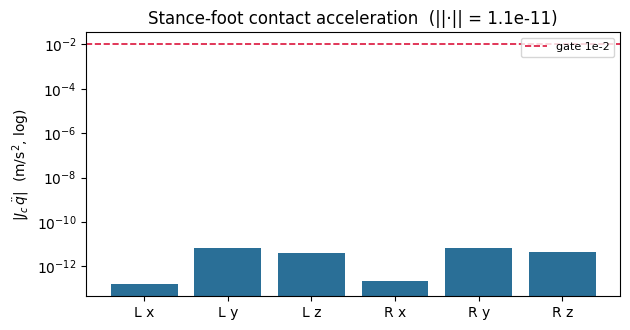

In [6]:
acc_left = contact_jacobian(model, q0, left_id) @ qdd     # (3,) x,y,z
acc_right = contact_jacobian(model, q0, right_id) @ qdd
contact_acc_norm = float(jnp.linalg.norm(jnp.concatenate([acc_left, acc_right])))

print("left  foot contact acceleration:", np.round(np.asarray(acc_left), 12))
print("right foot contact acceleration:", np.round(np.asarray(acc_right), 12))
print(f"||J_c qdd|| = {contact_acc_norm:.3e}  (GATE < 1e-2)")
assert contact_acc_norm < 1e-2, "feet are accelerating — contact task not enforced"

labels = ["L x", "L y", "L z", "R x", "R y", "R z"]
vals = np.abs(np.concatenate([np.asarray(acc_left), np.asarray(acc_right)]))
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(labels, np.maximum(vals, 1e-16), color="#2a6f97")
ax.set_yscale("log")
ax.axhline(1e-2, color="crimson", ls="--", lw=1.2, label="gate 1e-2")
ax.set_ylabel(r"$|J_c\,\ddot q|$  (m/s$^2$, log)")
ax.set_title(f"Stance-foot contact acceleration  (||·|| = {contact_acc_norm:.1e})")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

**Figure 2.** Per-axis magnitude of the stance-foot contact acceleration
$|J_c\,\ddot q|$ for both feet (log scale). Every component sits more than ten
orders of magnitude below the $10^{-2}$ gate (red dashed): with the contact
weight at $10^5$ the feet are pinned to numerical precision while the CoM and
momentum tasks share out the *remaining* freedom. This is the WBC doing its job
— honoring the hard objective first.

## 5. Did the CoM move where we asked?

The CoM acceleration the solution produces is $\big(A_G[3{:}6]/m\big)\,\ddot q$.
We compare it to the commanded acceleration $k_p\,(c_\text{des} - c)$. The
**direction** must match (we asked for $+y$); the **magnitude** will be far
smaller than the raw command — and that is the physically honest result: with
both feet hard-pinned, the body simply cannot fling its CoM sideways at the full
commanded rate. The contacts win, the CoM gets the best feasible $+y$ push. This
is "contact-vs-CoM infeasibility" showing up as attenuation, not as a failure.

achieved CoM accel : [-0.      0.0446  0.    ] m/s^2
commanded CoM accel: [0. 5. 0.] m/s^2
direction cosine(achieved, commanded) = 1.0000  (GATE > 0.5)
achieved +Y component = 0.0446  (GATE > 0)


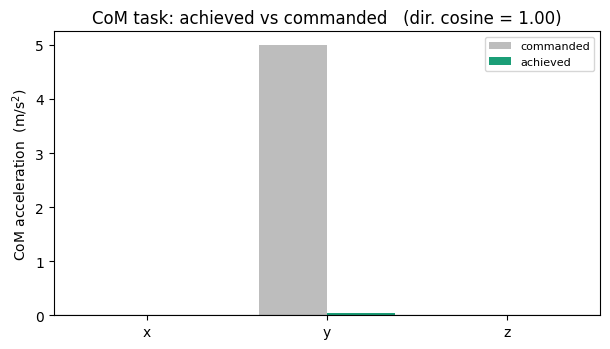

In [7]:
A_G = centroidal_momentum_matrix(model, q0)          # (6, nv)
com_acc = (A_G[3:6] / total_mass) @ qdd               # achieved CoM accel (3,)
com_acc_cmd = 100.0 * (com_desired - c0)              # commanded (kp*(cdes-c), kd*qd=0)

cos = float((com_acc @ com_acc_cmd) /
            (jnp.linalg.norm(com_acc) * jnp.linalg.norm(com_acc_cmd) + 1e-12))

print("achieved CoM accel :", np.round(np.asarray(com_acc), 4), "m/s^2")
print("commanded CoM accel:", np.round(np.asarray(com_acc_cmd), 4), "m/s^2")
print(f"direction cosine(achieved, commanded) = {cos:.4f}  (GATE > 0.5)")
print(f"achieved +Y component = {float(com_acc[1]):.4f}  (GATE > 0)")
assert float(com_acc[1]) > 0.0, "CoM moved the wrong way in Y"
assert cos > 0.5, "achieved CoM accel not aligned with command"

axes = ["x", "y", "z"]
x = np.arange(3); w = 0.38
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.bar(x - w/2, np.asarray(com_acc_cmd), w, label="commanded", color="#bdbdbd")
ax.bar(x + w/2, np.asarray(com_acc), w, label="achieved", color="#1b9e77")
ax.set_xticks(x); ax.set_xticklabels(axes)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel(r"CoM acceleration  (m/s$^2$)")
ax.set_title(f"CoM task: achieved vs commanded   (dir. cosine = {cos:.2f})")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Figure 3.** Commanded vs achieved CoM acceleration per axis. The
achieved acceleration points the right way — a positive $+y$ component aligned
with the command (direction cosine ≈ 1.0) — but is **much smaller in magnitude**
than the raw $k_p$ command. The hard contact constraints throttle how fast the
CoM can move; the WBC returns the largest $+y$ CoM push that still keeps both
feet planted. Direction tracks exactly; magnitude is bounded by feasibility.

## 6. The contact-weight trade-off

Weights *are* the priority knob. Sweep the contact weight from $10^1$ to $10^6$
and watch the contact residual $\lVert J_c\,\ddot q\rVert$ shrink: a heavier
contact weight buys a tighter foot constraint, at the expense of the CoM and
momentum tasks (whose weights we hold fixed). The soft-hierarchy promise —
$10\times$ weight $\approx 10\times$ tighter residual — should show up as a
clean roughly-decade-per-decade slope on a log–log plot.

  contact_w=  1e+01   ||J_c qdd||=1.146e-07   CoM+Y accel=0.0446
  contact_w=  1e+02   ||J_c qdd||=1.146e-08   CoM+Y accel=0.0446
  contact_w=  1e+03   ||J_c qdd||=1.146e-09   CoM+Y accel=0.0446
  contact_w=  1e+04   ||J_c qdd||=1.146e-10   CoM+Y accel=0.0446
  contact_w=  1e+05   ||J_c qdd||=1.146e-11   CoM+Y accel=0.0446
  contact_w=  1e+06   ||J_c qdd||=1.146e-12   CoM+Y accel=0.0446


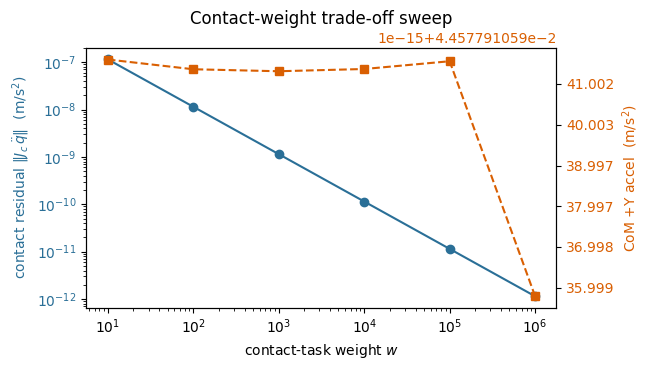

In [8]:
sweep_w = [1e1, 1e2, 1e3, 1e4, 1e5, 1e6]
contact_norms, com_y_accels = [], []
for w in sweep_w:
    s = build_solver(w)
    qd_w = s.solve(q0, qd0, nv)
    cn = float(jnp.linalg.norm(jnp.concatenate([
        contact_jacobian(model, q0, left_id) @ qd_w,
        contact_jacobian(model, q0, right_id) @ qd_w,
    ])))
    cy = float(((A_G[3:6] / total_mass) @ qd_w)[1])
    contact_norms.append(cn)
    com_y_accels.append(cy)

for w, cn, cy in zip(sweep_w, contact_norms, com_y_accels):
    print(f"  contact_w={w:>7.0e}   ||J_c qdd||={cn:.3e}   CoM+Y accel={cy:.4f}")

mono = all(contact_norms[i+1] <= contact_norms[i] * 1.05 + 1e-12
           for i in range(len(contact_norms) - 1))
assert mono, "contact residual should not grow as contact weight grows"
assert contact_norms[0] > contact_norms[-1] * 5, "weight had little effect"

fig, ax1 = plt.subplots(figsize=(6.6, 3.8))
ax1.loglog(sweep_w, contact_norms, "o-", color="#2a6f97", label=r"$\|J_c\,\ddot q\|$")
ax1.set_xlabel("contact-task weight $w$")
ax1.set_ylabel(r"contact residual $\|J_c\,\ddot q\|$  (m/s$^2$)", color="#2a6f97")
ax1.tick_params(axis="y", labelcolor="#2a6f97")
ax2 = ax1.twinx()
ax2.semilogx(sweep_w, com_y_accels, "s--", color="#d95f02", label="CoM +Y accel")
ax2.set_ylabel("CoM +Y accel  (m/s$^2$)", color="#d95f02")
ax2.tick_params(axis="y", labelcolor="#d95f02")
ax1.set_title("Contact-weight trade-off sweep")
fig.tight_layout()
plt.show()

**Figure 4.** Contact-weight sweep. The contact residual (blue, left axis)
falls almost exactly one decade per decade of weight — the soft-hierarchy
$10\times$-weight-$\approx$-$10\times$-tighter promise, made visible. The CoM
$+y$ acceleration (orange, right axis) is essentially flat across the sweep here:
even the *lowest* contact weight already dominates the much-smaller CoM and
momentum weights, so the feet are well-pinned throughout and the CoM gets a
consistent feasible push. Crank the contact weight far enough and the QP becomes
numerically stiff — the practical reason real WBCs cap contact weight rather
than sending it to infinity.

## Failure modes

The QP always returns *something*; the skill is recognizing when that something
is meaningless. Three failure modes to watch:

- **Conflicting tasks.** Two tasks that cannot both be satisfied (e.g. "hold the
  pelvis fixed" *and* "shift the CoM 30 cm" with both feet pinned) do not error —
  the QP silently returns a weighted compromise that satisfies *neither*. The
  symptom is a large CoM residual *and* a non-trivial contact residual at once.
  The fix is the weights: decide which objective is allowed to give, and say so
  numerically. We saw a benign version of this in §5 — the CoM magnitude is
  attenuated because the (heavier) contacts win.

- **Rank-deficient task stack.** If the stacked Jacobian $J$ does not span
  $\mathbb{R}^{n_v}$ — too few tasks, or tasks that are linearly dependent — then
  $H = J^\top J$ is singular along the unconstrained directions. Those joint
  accelerations are pinned only by the ridge $\varepsilon$; they are effectively
  arbitrary. The symptom is a $\ddot q$ with large components in joints no task
  touches. The ridge keeps the solve *finite*, not *meaningful* — add a
  low-weight posture-style regularizer to define the null space on purpose.

- **Contact vs CoM infeasibility.** With both feet hard-pinned, the CoM can only
  move within the support polygon's instantaneous reach. Command it past that and
  no $\ddot q$ satisfies both — the QP attenuates the CoM command (exactly §5).
  The honest read is *feasibility*, not a solver bug: if you need a bigger CoM
  excursion, you must **release a contact** (lift a foot — the swing phase Parts
  4–5 add) rather than push harder on a frozen base.

## Exercises

1. **Lift a foot.** Set the right `ContactTask` weight to $0$ (or use the
   `active` gate) so only the left foot is planted. Re-solve and inspect
   $J_{c,\text{right}}\,\ddot q$ — it is now free to be non-zero. How does the
   CoM $+y$ tracking change with one foot off the ground?

2. **Push the CoM until it breaks.** Sweep `LAT_SHIFT` from 0.01 m to 0.30 m and
   plot achieved-vs-commanded CoM $+y$ acceleration. Where does the achieved
   value saturate? That knee is the instantaneous reach of double support.

3. **Add a conflicting task.** Add a CoM task that commands $-y$ and another that
   commands $+y$ with equal weight. Confirm the QP returns ≈ 0 CoM acceleration
   and explain why in terms of the normal equations.

4. **Make the stack rank-deficient.** Remove the momentum task and one contact
   task, then look at the norm of $\ddot q$ on the arm joints (which no remaining
   task constrains). Add a small-weight `MomentumTask` back and watch them
   collapse. This is the role of regularization, made concrete.

## References

- L. Sentis & O. Khatib, *Synthesis of whole-body behaviors through hierarchical
  control of behavioral primitives*, Int. J. Humanoid Robotics, 2005 — the
  operational-space / prioritized whole-body formulation behind task-space WBC.
- O. Khatib, *A unified approach for motion and force control of robot
  manipulators: the operational space formulation*, IEEE J. Robotics &
  Automation, 1987 — the operational-space foundation.
- S. Kuindersma et al., *Optimization-based locomotion planning, estimation, and
  control design for the Atlas humanoid robot*, Autonomous Robots, 2016 — the
  canonical QP-based whole-body controller on a real biped (contacts, momentum,
  friction cones).
- D. E. Orin, A. Goswami & S.-H. Lee, *Centroidal dynamics of a humanoid robot*,
  Autonomous Robots, 2013 — the centroidal momentum matrix $A_G$ used by the
  contact and momentum tasks here.
- **Pink** / **Mink** (S. Caron et al.) — differential-IK / soft-weighted
  whole-body QP libraries; the soft-hierarchy weighting jaxterity's `WBCSolver`
  follows.

## Next steps → Part 4

We validated the **instantaneous** WBC map: task objectives in, joint
accelerations $\ddot q$ out, verified against contact, CoM, and momentum.
**Part 4** closes two gaps this part left open on purpose:

1. **Inverse dynamics** — turn $\ddot q$ into joint torques $\tau$ through the
   full equations of motion, with the contact wrench solved subject to the
   **friction cone** and joint **torque limits**. That is the step that makes the
   WBC something a motor can actually execute.
2. **Closed-loop MJX stepping** — feed the controller back into the simulator and
   watch balance (and then a step) emerge over time, using the Part 1–2 reduced
   plan as the reference generator and this WBC as the tracker.

Then Part 5 takes the calibrated, controlled robot toward deployment — the
handoff to **jaxility**.